In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

# Importing DataSet

In [118]:
df=pd.read_csv("/content/ecommerce_reviews_classification.csv")

In [119]:
df

,review_id,rating_dup,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id
0,R90000,5.0,20105.0,positive,125.0,5.0,Good roduct,No,1033.0
1,R90001,5.0,NaN,positive,80.0,5.0,Terrible quality,No,1080.0
2,R90002,4.0,20356.0,positive,21.0,4.0,NaN,No,1074.0
3,R90003,5.0,20007.0,positive,189.0,5.0,Excellent!,Yes,1092.0
4,R90004,5.0,20261.0,positive,55.0,5.0,Not as expected,Yes,1033.0
...,...,...,...,...,...,...,...,...,...
260,R90056,NaN,20386.0,neutral,14.0,NaN,Terrible quality,Yes,1017.0
261,R90153,4.0,20087.0,positive,197.0,4.0,Terrible quality,No,1064.0
262,R90032,5.0,20481.0,positive,43.0,5.0,Value for money,YES,1088.0
263,R90096,5.0,20173.0,positive,74.0,5.0,Would buy again,No,1080.0


There are total 265 rows and
 among there 4 categorical columns and 5 numerical columns

In [120]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          251 non-null    object 
 1   rating_dup         256 non-null    float64
 2   user_id            252 non-null    float64
 3   sentiment          252 non-null    object 
 4   helpful_votes      248 non-null    float64
 5   rating             256 non-null    float64
 6   review_text        245 non-null    object 
 7   verified_purchase  246 non-null    object 
 8   product_id         253 non-null    float64
dtypes: float64(5), object(4)
memory usage: 18.8+ KB


# Handaling outliers

Checking the numerical columns to check wheather there were present outliers or not

In [121]:
df.select_dtypes(include=['number']).columns

Index(['rating_dup', 'user_id', 'helpful_votes', 'rating', 'product_id'], dtype='object')

In [122]:
for col in ['user_id', 'helpful_votes', 'rating', 'product_id']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

user_id Outliers: 0
helpful_votes Outliers: 0
rating Outliers: 0
product_id Outliers: 0


# Handling Duplicate rows and columns

while observing here we are having duplicate column as rating_dup id duplicate column of the rating column

In [123]:
df.drop('rating_dup', axis=1, inplace=True)

Review_id is the unique column so there may exist duplicates so we should drop them

In [124]:
df['review_id'].duplicated().sum()

np.int64(28)

In [125]:
df.drop_duplicates(subset=['review_id'], keep='first', inplace=True)

In [126]:
df[df.duplicated(keep=False)]

,review_id,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 237 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            225 non-null    float64
 2   sentiment          227 non-null    object 
 3   helpful_votes      221 non-null    float64
 4   rating             230 non-null    float64
 5   review_text        219 non-null    object 
 6   verified_purchase  221 non-null    object 
 7   product_id         228 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.7+ KB


# Handling Missing Values

review_id,product_id,user_id is a unique identifier. We can't fill it using mean, median or mode.

In [128]:
df.isnull().sum()

,0
review_id,1
user_id,12
sentiment,10
helpful_votes,16
rating,7
review_text,18
verified_purchase,16
product_id,9


In [129]:
df['helpful_votes'].fillna(df['helpful_votes'].median())
df['rating'] = df['rating'].fillna(df['rating'].mode()[0])

In [130]:
df['review_text'] = df['review_text'].fillna('')

In [131]:
df['verified_purchase'].unique()

array(['No', 'Yes', nan, 'Ye', 'Ys', 'YES', 'es', 'NO', 'o', 'N'],
      dtype=object)

In [132]:
df['verified_purchase'] = (df['verified_purchase'].str.strip().str.lower().replace({'yes': 'Yes','y': 'Yes','no': 'No','n': 'No','ye':'Yes','ys':'Yes','es':'Yes','o':'No'}))

In [133]:
df['verified_purchase'].unique()

array(['No', 'Yes', nan], dtype=object)

In [134]:
df['verified_purchase'] = df['verified_purchase'].fillna(df['verified_purchase'].mode()[0])

In [135]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 237 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            225 non-null    float64
 2   sentiment          227 non-null    object 
 3   helpful_votes      221 non-null    float64
 4   rating             237 non-null    float64
 5   review_text        237 non-null    object 
 6   verified_purchase  237 non-null    object 
 7   product_id         228 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.7+ KB


In [136]:
df.isnull().sum()

,0
review_id,1
user_id,12
sentiment,10
helpful_votes,16
rating,0
review_text,0
verified_purchase,0
product_id,9


In categorical we are having sentiment column which we can't predict and replace the nan with simply mode so it is preferable to drop the rows

In [137]:
df = df[df['sentiment'].notna()]

In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 227 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          226 non-null    object 
 1   user_id            216 non-null    float64
 2   sentiment          227 non-null    object 
 3   helpful_votes      211 non-null    float64
 4   rating             227 non-null    float64
 5   review_text        227 non-null    object 
 6   verified_purchase  227 non-null    object 
 7   product_id         218 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.0+ KB


the review_id is having missing value so we dropped and arranged the values

In [ ]:
df.insert(0, 'review_id',['R' + str(i) for i in np.arange(9000, 9000 + len(df))])

**downloading of preprocessed data set**

In [140]:
df.to_csv('preprocessed_ecommerce_reviews.csv', index=False)

**Importing the data set**

In [141]:
df = pd.read_csv("/content/preprocessed_ecommerce_reviews.csv")

In [142]:
df.describe()

,user_id,helpful_votes,rating,product_id
count,216.000000,211.000000,227.000000,218.000000
mean,20254.615741,97.957346,3.687225,1048.912844
std,141.043637,57.501578,1.224371,28.480679
min,20002.000000,0.000000,1.000000,1000.000000
25%,20138.750000,53.000000,3.000000,1025.250000
50%,20265.500000,93.000000,4.000000,1049.000000
75%,20374.250000,147.000000,5.000000,1072.750000
max,20499.000000,199.000000,5.000000,1099.000000


# Univariate Analysis

**Numerical_Columns**

Univariate Analysis: Numerical columns
1. Count Plot: The chart shows the frequency of each category or rating in the dataset.

2. Histogram: The histogram displays the distribution and frequency of numerical values in the dataset.

3. KDE Plot: The KDE curve shows the overall distribution and concentration of the data values.

4. Box Plot: The box plot displays the median, data spread, and potential outliers in the dataset.

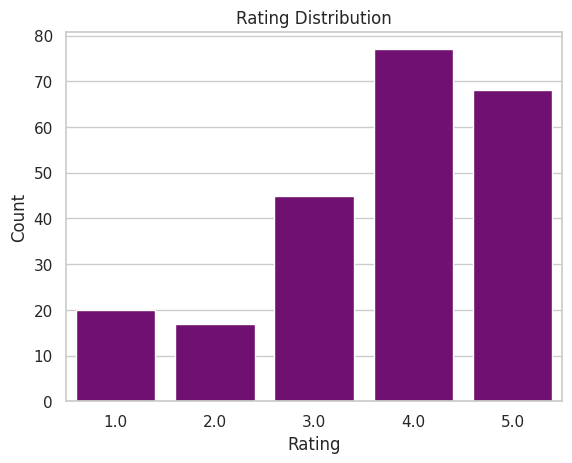

In [143]:
sns.countplot(data=df, x='rating',color="purple")
plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

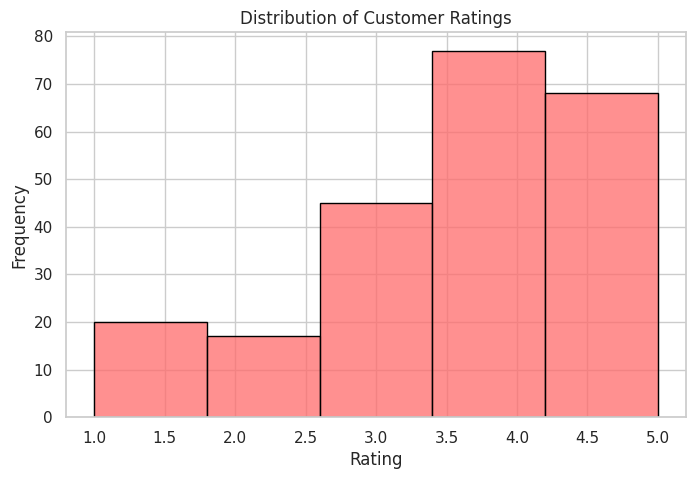

In [144]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x='rating',bins=5,color='#FF6B6B',edgecolor='black')
plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

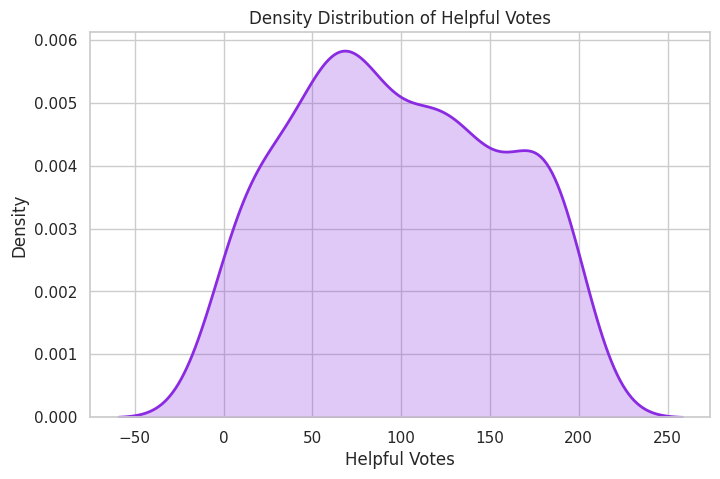

In [145]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=df,x='helpful_votes',fill=True,color='#8A2BE2',linewidth=2)
plt.title('Density Distribution of Helpful Votes')
plt.xlabel('Helpful Votes')
plt.ylabel('Density')
plt.show()

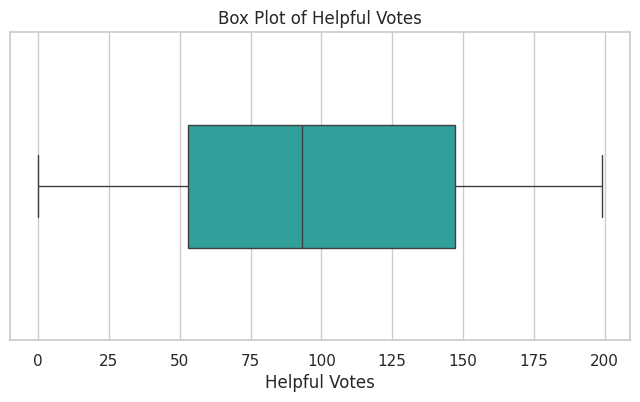

In [146]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df,x='helpful_votes',color='#20B2AA',width=0.4)
plt.title('Box Plot of Helpful Votes')
plt.xlabel('Helpful Votes')
plt.show()

**Categorical_columns**

5. Pie Chart: The pie chart shows the proportion of each category in the dataset, highlighting its contribution to the total.

6. Horizontal Bar Chart: The chart compares the frequency of different categories, making it easy to identify the most and least common categories.

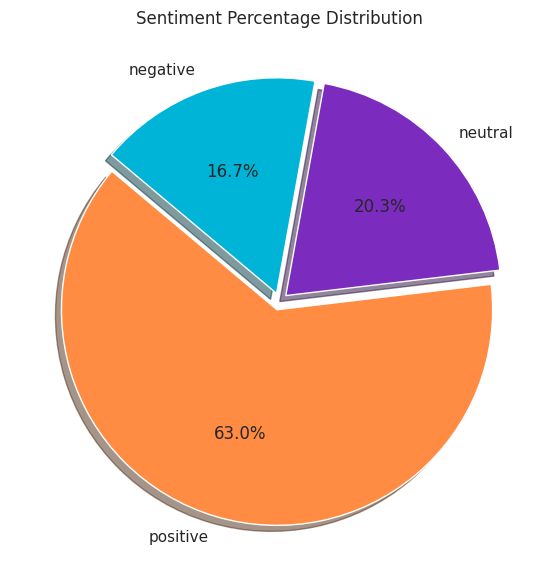

In [147]:
sentiment_counts = df['sentiment'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(sentiment_counts,labels=sentiment_counts.index,autopct='%1.1f%%',startangle=140,colors=['#FF8C42', '#7B2CBF', '#00B4D8'],explode=[0.04] * len(sentiment_counts),shadow=True)
plt.title('Sentiment Percentage Distribution')
plt.show()

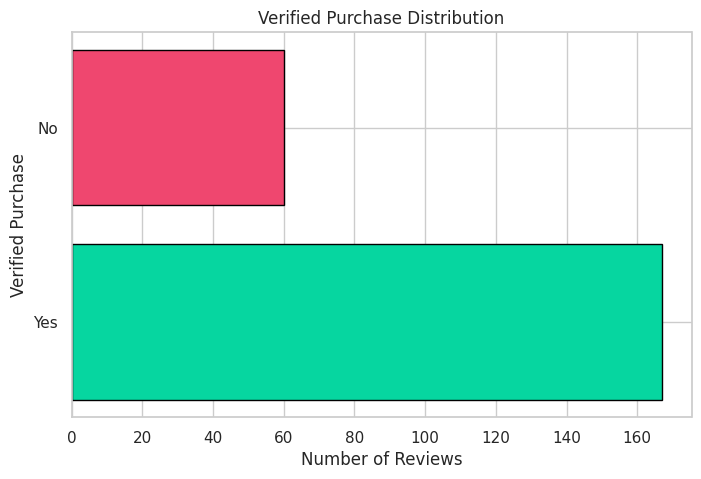

In [148]:
purchase_counts = df['verified_purchase'].value_counts()
plt.figure(figsize=(8,5))
plt.barh(purchase_counts.index,purchase_counts.values,color=['#06D6A0', '#EF476F'],edgecolor='black')
plt.title('Verified Purchase Distribution')
plt.xlabel('Number of Reviews')
plt.ylabel('Verified Purchase')
plt.show()

# Bivariate Analysis

**Numerical vs Numerical Analysis**

1. Scatter Plot: The chart shows the relationship between two numerical variables and helps identify patterns or trends.

2. Joint Plot: The joint plot displays the relationship between two numerical variables along with their individual distributions.

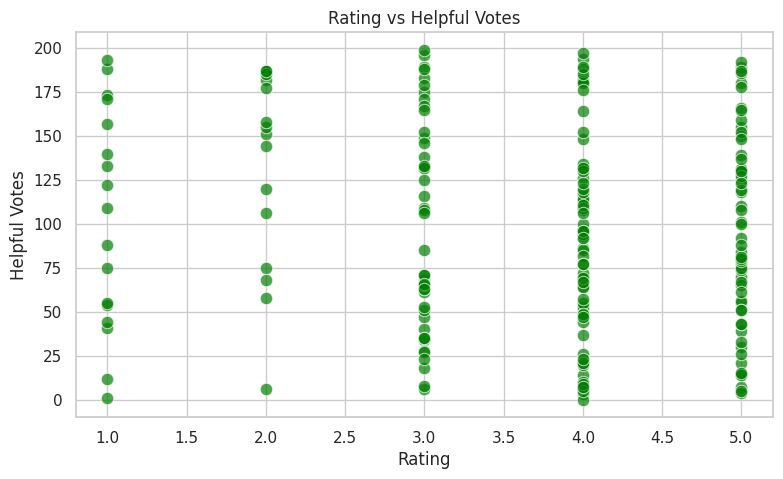

In [149]:
plt.figure(figsize=(9,5))
sns.scatterplot(data=df,x='rating',y='helpful_votes',color='green',s=80,alpha=0.7)
plt.title('Rating vs Helpful Votes')
plt.xlabel('Rating')
plt.ylabel('Helpful Votes')
plt.show()

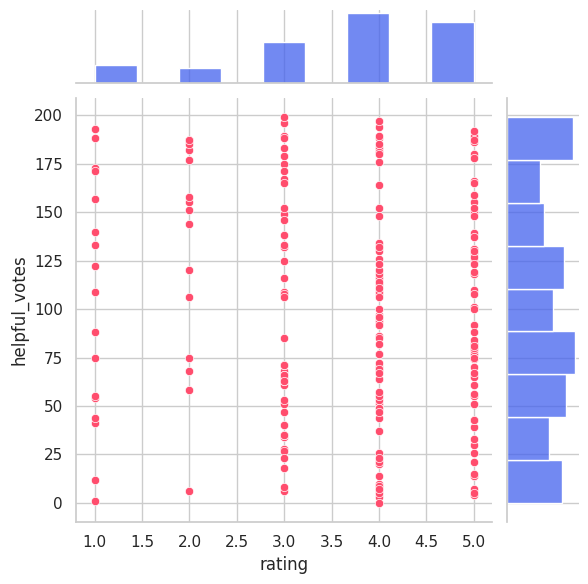

In [150]:
sns.jointplot(data=df,x='rating',y='helpful_votes',kind='scatter',color='#FF4D6D',marginal_kws={'color': '#4361EE'})
plt.show()

**Categorical vs Numerical Analysis**

1. Box Plot: The chart compares the distribution, median, spread, and potential outliers of numerical values across categories.

2. Violin Plot: The chart shows the distribution and density of numerical values across different categories.

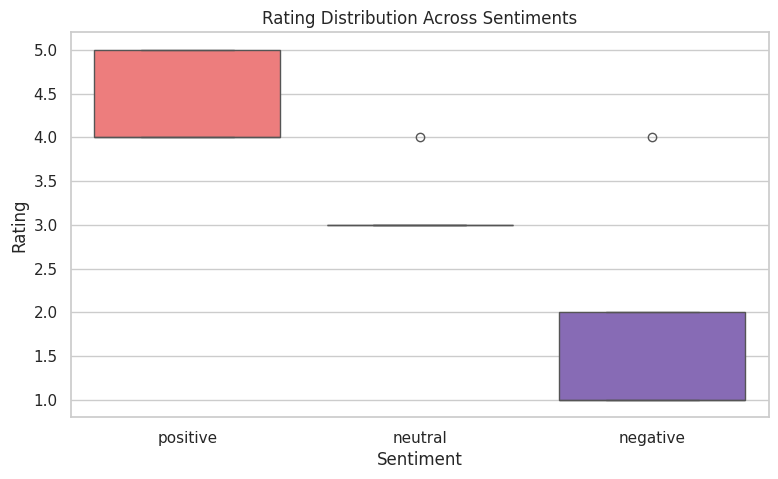

In [151]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df,x='sentiment',y='rating',hue='sentiment',palette=['#FF6B6B', '#4ECDC4', '#845EC2'],legend=False)
plt.title('Rating Distribution Across Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Rating')
plt.show()

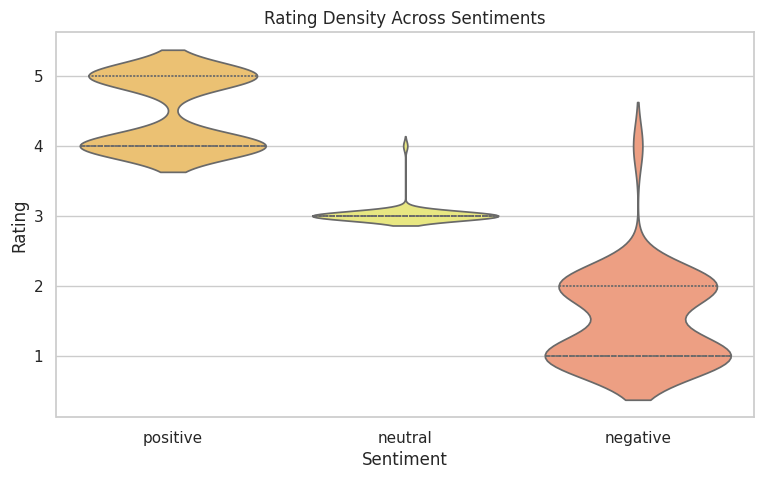

In [152]:
plt.figure(figsize=(9,5))
sns.violinplot(data=df,x='sentiment',y='rating',hue='sentiment',palette=['#FFC75F', '#F9F871', '#FF9671'],inner='quartile',legend=False)
plt.title('Rating Density Across Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Rating')
plt.show()

**Categorical vs Categorical Analysis**

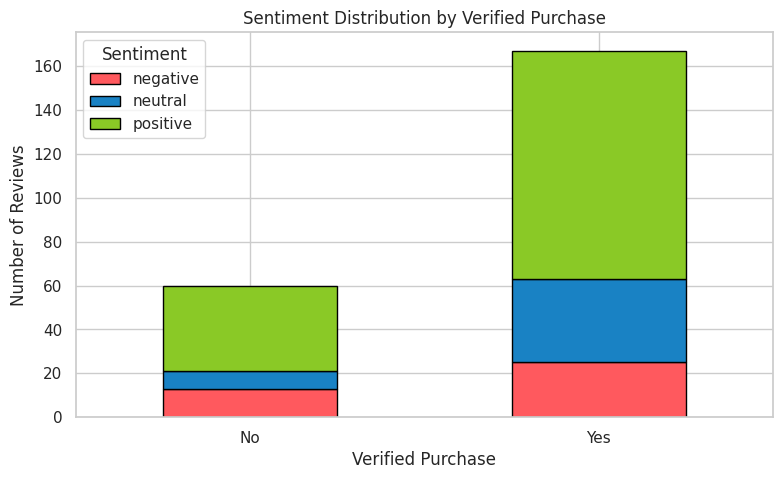

In [153]:
ct = pd.crosstab(df['verified_purchase'],df['sentiment'])
ct.plot(kind='bar',stacked=True,figsize=(9,5),color=['#FF595E', '#1982C4', '#8AC926'],edgecolor='black')
plt.title('Sentiment Distribution by Verified Purchase')
plt.xlabel('Verified Purchase')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.show()

# Multivariate Analysis

1. Correlation Heatmap: The heatmap represents the strength and direction of relationships among multiple numerical variables using different colours.

2. Bubble Chart: The bubble chart shows the relationship between multiple variables, where bubble size and colour represent additional information.

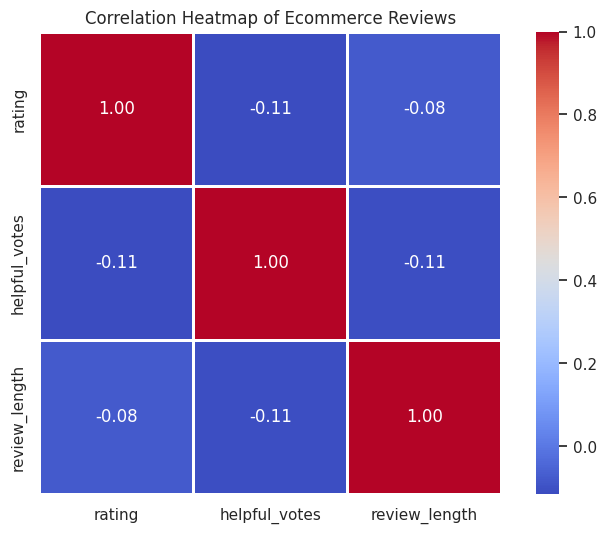

In [158]:
df['review_length'] = df['review_text'].fillna('').astype(str).str.len()
plt.figure(figsize=(9, 6))
corr = df[['rating', 'helpful_votes', 'review_length']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=2, fmt='.2f', square=True)
plt.title('Correlation Heatmap of Ecommerce Reviews')
plt.show()

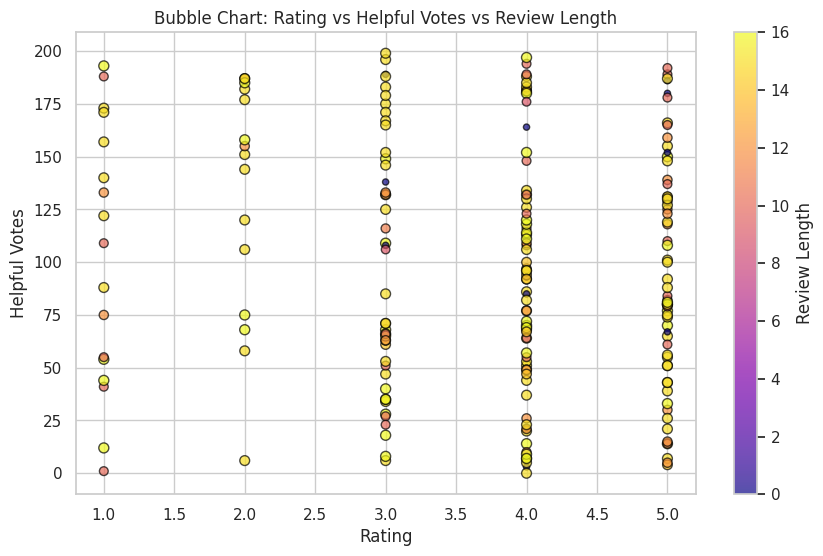

In [162]:
plt.figure(figsize=(10, 6))
plt.scatter(df['rating'],df['helpful_votes'],s=df['review_length'] * 2 + 20,c=df['review_length'],cmap='plasma',alpha=0.7,edgecolors='black')
plt.colorbar(label='Review Length')
plt.xlabel('Rating')
plt.ylabel('Helpful Votes')
plt.title('Bubble Chart: Rating vs Helpful Votes vs Review Length')
plt.show()

**Univariate , Bivariate and Multivariate analysis on single grid**

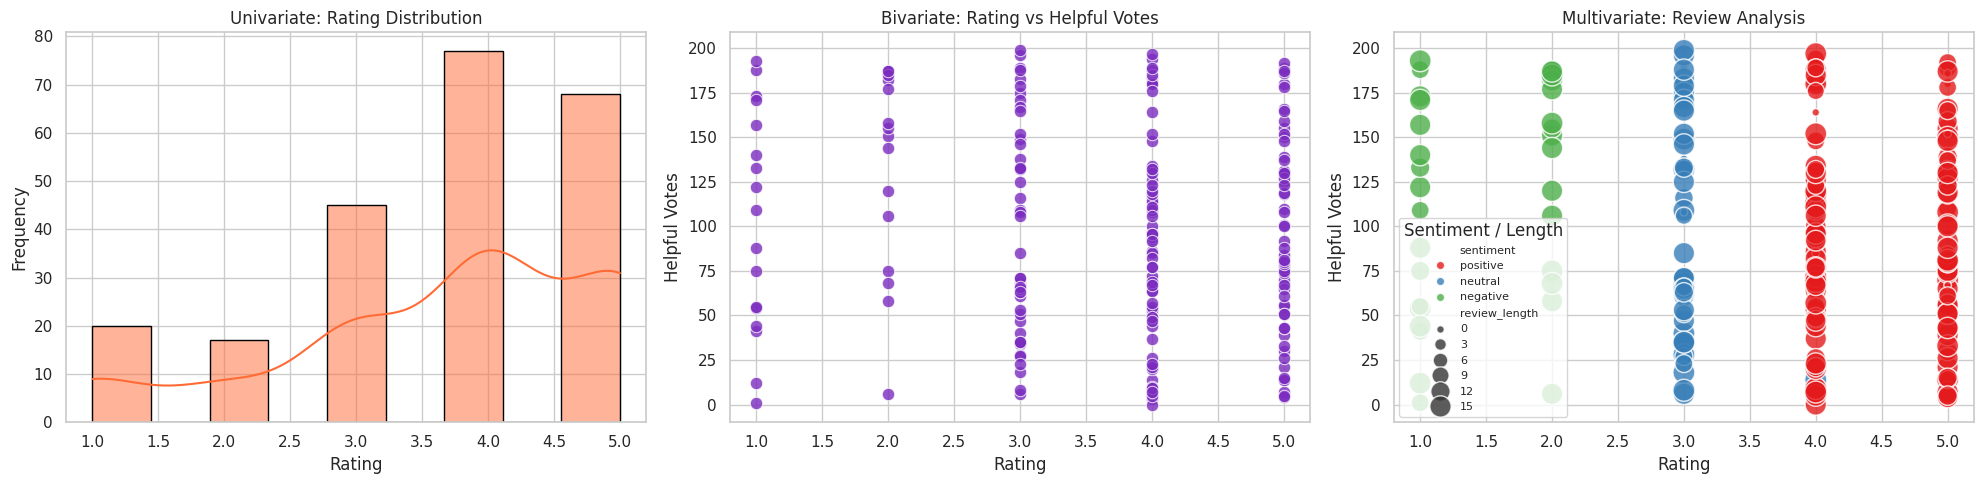

In [161]:

df['review_length'] = df['review_text'].fillna('').astype(str).str.len()
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
# 1. UNIVARIATE ANALYSIS
sns.histplot(data=df, x='rating', kde=True, color='#FF6B35', edgecolor='black', ax=axes[0])
axes[0].set_title('Univariate: Rating Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Frequency')
# 2. BIVARIATE ANALYSIS
sns.scatterplot(data=df, x='rating', y='helpful_votes', color='#7B2CBF', s=80, alpha=0.8, ax=axes[1])
axes[1].set_title('Bivariate: Rating vs Helpful Votes')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Helpful Votes')
# 3. MULTIVARIATE ANALYSIS
sns.scatterplot(data=df, x='rating', y='helpful_votes', hue='sentiment', size='review_length', sizes=(30, 250), palette='Set1', alpha=0.8, ax=axes[2])
axes[2].set_title('Multivariate: Review Analysis')
axes[2].set_xlabel('Rating')
axes[2].set_ylabel('Helpful Votes')
axes[2].legend(fontsize=8, title='Sentiment / Length')
plt.tight_layout()
plt.show()

# Complete Report

The Exploratory Data Analysis (EDA) was performed on the preprocessed ecommerce reviews dataset using univariate, bivariate, and multivariate analysis. Various visualizations were used to understand rating distributions, customer sentiment, review patterns, and helpful votes. The analysis also explored relationships between ratings, review length, sentiment, and verified purchases. These visualizations helped identify important patterns and understand customer feedback more effectively.